In [67]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
import tensorflow as tf
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import TargetEncoder, StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_validate, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, make_scorer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from keras import Sequential
from keras.layers import Dense, Input, Normalization
from keras.optimizers import Adam
from keras.losses import MeanSquaredError

In [68]:
dataset = pd.read_csv('../data/life_expectancy/Life Expectancy Data.csv')
dataset.head()

,Country,Year,Status,Life expectancy,Adult Mortality,infant deaths,Alcohol,percentage expenditure,Hepatitis B,Measles,...,Polio,Total expenditure,Diphtheria,HIV/AIDS,GDP,Population,thinness 1-19 years,thinness 5-9 years,Income composition of resources,Schooling
0,Afghanistan,2015,Developing,65.0,263.0,62,0.01,71.279624,65.0,1154,...,6.0,8.16,65.0,0.1,584.259210,33736494.0,17.2,17.3,0.479,10.1
1,Afghanistan,2014,Developing,59.9,271.0,64,0.01,73.523582,62.0,492,...,58.0,8.18,62.0,0.1,612.696514,327582.0,17.5,17.5,0.476,10.0
2,Afghanistan,2013,Developing,59.9,268.0,66,0.01,73.219243,64.0,430,...,62.0,8.13,64.0,0.1,631.744976,31731688.0,17.7,17.7,0.470,9.9
3,Afghanistan,2012,Developing,59.5,272.0,69,0.01,78.184215,67.0,2787,...,67.0,8.52,67.0,0.1,669.959000,3696958.0,17.9,18.0,0.463,9.8
4,Afghanistan,2011,Developing,59.2,275.0,71,0.01,7.097109,68.0,3013,...,68.0,7.87,68.0,0.1,63.537231,2978599.0,18.2,18.2,0.454,9.5


In [69]:
dataset.info()

<class 'pandas.DataFrame'>
RangeIndex: 2938 entries, 0 to 2937
Data columns (total 22 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Country                          2938 non-null   str    
 1   Year                             2938 non-null   int64  
 2   Status                           2938 non-null   str    
 3   Life expectancy                  2928 non-null   float64
 4   Adult Mortality                  2928 non-null   float64
 5   infant deaths                    2938 non-null   int64  
 6   Alcohol                          2744 non-null   float64
 7   percentage expenditure           2938 non-null   float64
 8   Hepatitis B                      2385 non-null   float64
 9   Measles                          2938 non-null   int64  
 10   BMI                             2904 non-null   float64
 11  under-five deaths                2938 non-null   int64  
 12  Polio                          

In [70]:
# Processing

# Remove missing values
dataset.dropna(inplace=True)

# Alternatively, we could imput replacement data
# dataset.fillna(dataset.mean(), inplace=True)

# Encoding
# Manual encoding using pandas
# Alternatively, we could use an encoder in scikit-learn e.g. OneHotEncoder
dataset['Status'] = dataset['Status'].replace({'Developing':0, 'Developed':1}).astype('int')

In [71]:
# We want to perform mean normalization. This should be done on the numerical features only, so
# it is helpful to have a list of all the numerical features
# Update: it would be nice to separate standard distributed numerical data from other distributions.
# As it is, Status has been converted to numerical data, but shouldn't be scaled using mean (standard) 
# normalization (scaling)
numerical_features = dataset.drop(['Country', 'Status', 'Life expectancy '], axis=1).columns
numerical_features

Index(['Year', 'Adult Mortality', 'infant deaths', 'Alcohol',
       'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ',
       'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ',
       ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years',
       ' thinness 5-9 years', 'Income composition of resources', 'Schooling'],
      dtype='str')

In [72]:
# Split our data into TrainValidation and Testing
dataset_trainval, dataset_test = train_test_split(dataset, test_size=0.4, shuffle=True)
features_trainval = dataset_trainval.drop('Life expectancy ', axis=1)
features_test = dataset_test.drop('Life expectancy ', axis=1)
targets_trainval = dataset_trainval['Life expectancy ']
targets_test = dataset_test['Life expectancy ']
# Print the shapes of the splits to ensure 60/40 split
print(features_trainval.shape)
print(features_test.shape)

(989, 21)
(660, 21)


In [73]:
# We store the unique values of Country in a list for future use in encoders
countries = list(dataset['Country'].unique())

In [74]:
# Perform target encoding on the training and validation data. This will cause a leak between the training and validation
# folds i.e. it can make the hyperparameter tuning produce results that are over optimistic, but after tuning with 
# GridSearchCV, the estimators are refitted on the entire trainval split i.e. there's no leakage to the final test split.
# Use a Pipeline to solve this issue and allow for a tunable pipeline (see below)
# Fit on trainval data
country_targetencoder = TargetEncoder(categories=[countries]).fit(features_trainval[['Country']], targets_trainval)
features_trainval_targetencoded = features_trainval.copy()
features_test_targetencoded = features_test.copy()
# Transform the splits using the trained target encoder
features_trainval_targetencoded['Country'] = country_targetencoder.transform(features_trainval[['Country']])
features_test_targetencoded['Country'] = country_targetencoder.transform(features_test[['Country']])

# Create a new list of numerical features where the target encoded Country feature is included since
# it makes sense to normalize/scale this feature if scaling is employed
numerical_features_targetencoded = numerical_features.append(pd.Index(['Country']))

In [75]:
# Create a separate copy of the dataset where onehot encoding is used instead of target encoding.

country_onehotencoder = OneHotEncoder(categories=[countries]).fit(features_trainval[['Country']], targets_trainval)
columns = country_onehotencoder.get_feature_names_out(['Country'])
features_trainval_onehotencoded = features_trainval.copy()
features_test_onehotencoded = features_test.copy()
# Transform the splits using the trained target encoder
onehot_countries_trainval = pd.DataFrame(country_onehotencoder.transform(features_trainval[['Country']]).toarray(), index=features_trainval.index, columns=columns)
onehot_countries_test = pd.DataFrame(country_onehotencoder.transform(features_test[['Country']]).toarray(), index=features_test.index, columns=columns)
features_trainval_onehotencoded = features_trainval_onehotencoded.drop('Country', axis=1)
features_test_onehotencoded = features_test_onehotencoded.drop('Country', axis=1)
features_trainval_onehotencoded = pd.concat([features_trainval_onehotencoded, onehot_countries_trainval], axis=1)
features_test_onehotencoded = pd.concat([features_test_onehotencoded, onehot_countries_test], axis=1)

In [76]:
# Create a function that test the performance on the test split
def test_targetencoded(model):
    predictions = model.predict(features_test_targetencoded)
    print(f'MSE: {mean_squared_error(targets_test, predictions)}')
    print(f'MAE: {mean_absolute_error(targets_test, predictions)}')
    print(f'R2: {r2_score(targets_test, predictions)}')


In [77]:
# Pipelines

# Create a pipeline that has a ColumnTransformer before the estimator. We specify the 
# names and types of each step in the pipeline
# Update: Made sure that features not contained in the specific column transformers are 
# passed through without change. The default behavior is to drop them
dt_pipe = Pipeline([
    ('encode', ColumnTransformer([('country', TargetEncoder(), ['Country']), ('numerical', 'passthrough', numerical_features)], remainder='passthrough')), 
    ('estimator', DecisionTreeRegressor())
])
# Check the names (and values) of the tunable parameters
# Note that each step in the pipeline are available by their specified 
# names, and that the parameter of each step is accessible through __ 
# e.g. estimator__max_depth
dt_pipe.get_params()

{'memory': None,
 'steps': [('encode',
   ColumnTransformer(remainder='passthrough',
                     transformers=[('country', TargetEncoder(), ['Country']),
                                   ('numerical', 'passthrough',
                                    Index(['Year', 'Adult Mortality', 'infant deaths', 'Alcohol',
          'percentage expenditure', 'Hepatitis B', 'Measles ', ' BMI ',
          'under-five deaths ', 'Polio', 'Total expenditure', 'Diphtheria ',
          ' HIV/AIDS', 'GDP', 'Population', ' thinness  1-19 years',
          ' thinness 5-9 years', 'Income composition of resources', 'Schooling'],
         dtype='str'))])),
  ('estimator', DecisionTreeRegressor())],
 'transform_input': None,
 'verbose': False,
 'encode': ColumnTransformer(remainder='passthrough',
                   transformers=[('country', TargetEncoder(), ['Country']),
                                 ('numerical', 'passthrough',
                                  Index(['Year', 'Adult Mortality', 

In [78]:

# Specify the parameter grid. Made up of te parameter names to tune and the 
# corresponding values to try.
dt_pipe_params = {
    'estimator__max_depth': [2, 8, 16], 
    # Update: We specify the total list of categories. This fixes the issues we had with 
    # folds not having rare values
    'encode__country': [TargetEncoder(categories=[countries]), OneHotEncoder(categories=[countries])],
    'encode__numerical': ['passthrough', StandardScaler(), MinMaxScaler()]
}
dt_pipe_grid = GridSearchCV(dt_pipe, dt_pipe_params)
dt_pipe_grid.fit(features_trainval, targets_trainval)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'encode__country': [TargetEncoder...ombia', ...]]), OneHotEncoder...ombia', ...]])], 'encode__numerical': ['passthrough', StandardScaler(), ...], 'estimator__max_depth': [2, 8, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` de

In [79]:
# We create a new test function for testing pipelines. The difference is that 
# this uses the unencoded test data since the encoding is left to the pipeline
def test(pipe):
    predictions = pipe.predict(features_test)
    print(f'MSE: {mean_squared_error(targets_test, predictions)}')
    print(f'MAE: {mean_absolute_error(targets_test, predictions)}')
    print(f'R2: {r2_score(targets_test, predictions)}')

In [80]:
test(dt_pipe_grid)

MSE: 4.669964273890162
MAE: 1.3040609012199922
R2: 0.937948770638535


In [81]:
# Neural Networks 

# Train a simple neural network (MLPRegressor)

# Our hyperparameter grid. See the documentaion for details
nn_params = {
    # 'solver': ['adam', 'lbfgs'],
    'hidden_layer_sizes': [(20,), (20, 10), (20, 15, 10, 5)]
}

# Tune with target encoded values
# This causes issues. Most likely due to not having scaled the numerical features
# Update: Apparently, the target encoder also causes issues
nn_grid = GridSearchCV(MLPRegressor(max_iter=500), nn_params)
nn_grid.fit(features_trainval_targetencoded, targets_trainval)
test_targetencoded(nn_grid)

/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


MSE: 386998331.8516389
MAE: 4606.136006556112
R2: -5142163.017504689


In [82]:
# Create a pipeline with two steps; a preprocessor and the estimator. The preprocessor has 
# two groups of transformers; one for categorical columns and one for numerical.
nn2_pipe = Pipeline([
    ('preprocess', ColumnTransformer([
        ('categorical', OneHotEncoder(categories=[countries]), ['Country']), 
        ('numerical', StandardScaler(), numerical_features)], 
        remainder='passthrough')), 
    ('estimator', MLPRegressor())
])

# Specify the parameter grid. This tries four different versions of the dataset and tests each 
# of these with six different neural networks
nn2_params = {
    # OneHot vs. TargetEncoder
    'preprocess__categorical': [OneHotEncoder(categories=[countries]), TargetEncoder(categories=[countries])],
    # Mean normalization vs. min-max
    'preprocess__numerical': [StandardScaler(), MinMaxScaler()],
    # Adam optimizer vs LBFGS (both are stochistic alternatives)
    'estimator__solver': ['adam', 'lbfgs'],
    # Three different architectures
    'estimator__hidden_layer_sizes': [(20,), (20, 10), (20, 15, 10, 5)]
}

# Train and tune. Retrains with best parameters on entire trainval
nn2_pipe_grid = GridSearchCV(nn2_pipe, nn2_params)
nn2_pipe_grid.fit(features_trainval, targets_trainval)

/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(
/home/lars/Documents/itf31519_2026/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization has

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...Regressor())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'estimator__hidden_layer_sizes': [(20,), (20, ...), ...], 'estimator__solver': ['adam', 'lbfgs'], 'preprocess__categorical': [OneHotEncoder...ombia', ...]]), TargetEncoder...ombia', ...]])], 'preprocess__numerical': [StandardScaler(), MinMaxScaler()]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validatio

In [83]:
# Trying to identify which parameters cause non-convergence
nn2_pipe_results = pd.DataFrame(nn2_pipe_grid.cv_results_)
nn2_pipe_results

,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_estimator__hidden_layer_sizes,param_estimator__solver,param_preprocess__categorical,param_preprocess__numerical,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
0,0.389863,0.004038,0.006226,0.000470,"(20,)",adam,"OneHotEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",-7.889160,-7.553146,-13.529651,-7.036396,-5.042910,-8.210253,2.836931,23
1,0.365466,0.004541,0.005696,0.000102,"(20,)",adam,"OneHotEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",-0.333393,-3.748589,0.053952,-0.143656,0.150459,-0.804245,1.481567,22
2,0.223502,0.001518,0.004609,0.000085,"(20,)",adam,"TargetEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",0.926020,0.953744,0.936178,0.938323,0.945167,0.939886,0.009256,11
3,0.226284,0.003050,0.004870,0.000410,"(20,)",adam,"TargetEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",0.929124,0.933784,0.919856,0.909136,0.916912,0.921762,0.008778,16
4,0.168105,0.003984,0.006472,0.000223,"(20,)",lbfgs,"OneHotEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",0.941942,0.950532,0.930681,0.941780,0.956431,0.944273,0.008756,4
5,0.163073,0.002314,0.006252,0.000203,"(20,)",lbfgs,"OneHotEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",0.946383,0.961849,0.946056,0.946885,0.957882,0.951811,0.006700,1
6,0.100834,0.002234,0.004680,0.000193,"(20,)",lbfgs,"TargetEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",0.923826,0.954227,0.939761,0.940899,0.947741,0.941291,0.010163,6
7,0.114920,0.012003,0.004657,0.000163,"(20,)",lbfgs,"TargetEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),"{'estimator__hidden_layer_sizes': (20,), 'esti...",0.932300,0.955299,0.941494,0.942953,0.945939,0.943597,0.007415,5
8,0.452942,0.006623,0.005941,0.000327,"(20, 10)",adam,"OneHotEncoder(categories=[['Afghanistan', 'Alb...",StandardScaler(),"{'estimator__hidden_layer_sizes': (20, 10), 'e...",0.263956,0.182213,-0.406097,-0.639506,0.477469,-0.024393,0.424678,21
9,0.446402,0.006938,0.005839,0.000073,"(20, 10)",adam,"OneHotEncoder(categories=[['Afghanistan', 'Alb...",MinMaxScaler(),"{'estimator__hidden_layer_sizes': (20, 10), 'e...",0.404905,0.480699,0.491115,0.497654,0.602218,0.495318,0.062990,20


In [84]:
test(nn2_pipe_grid)

MSE: 3.2288058836258435
MAE: 1.111402644805243
R2: 0.9570978785493751


In [85]:
# TensorFlow

# Start by converting the data to tensors. Tensors are capable of being moved to
# GPU/TPU
features_trainval_tensor = tf.convert_to_tensor(features_trainval_targetencoded)
features_test_tensor = tf.convert_to_tensor(features_test_targetencoded)
targets_trainval_tensor = tf.convert_to_tensor(targets_trainval)
targets_test_tensor = tf.convert_to_tensor(targets_test)

# Print shape for debugging purposes
print(features_test_tensor.shape)
print(targets_test_tensor.shape)

(660, 21)
(660,)


In [86]:
# Create a simple network that is similar to the best MLPRegressor

# Create a normalization layer and train it on or trainval data
knn_normalization = Normalization()
knn_normalization.adapt(features_trainval_tensor)

# Create a simple network with a single hidden layer with relu activation
# The input and output (first and last layer) are direct consequence of the structure of the data
# and type of problem
knn = Sequential([
    Input(shape=(21,)),
    knn_normalization,
    Dense(20, activation='relu'), 
    Dense(1, activation='linear')
])

# Finalize the network by specifying the optimizer to use for training the weights and the loss function. 
# We also specify a metric for additional measurements, but this isn't required
knn.compile(optimizer=Adam(learning_rate=1e-3), loss=MeanSquaredError(), metrics=['mean_absolute_error'])

# Show a summary of the network
knn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ normalization_2 (Normalization) │ (None, 21)             │            43 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 20)             │           440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 504 (1.97 KB)

 Trainable params: 461 (1.80 KB)

 Non-trainable params: 43 (176.00 B)

In [90]:
# The training is wrapped in a serialization test for saving time for 
# long-running cells. Delete the serialized model knn.keras to re-run.

# If the file doesn't exists i.e. the training hasn't been run
if not os.path.isfile('knn.keras'):
    # Train the network using a batch size of 10 (number of instances to see before updating 
    # weights). The number of epochs control how many iterations through the training data
    knn.fit(features_trainval_tensor, targets_trainval_tensor, epochs=100, batch_size=10)
    # Save the model
    knn.save('knn.keras')
# If the model has already been trained and serialized
else: 
    knn = tf.keras.models.load_model('knn.keras')

# Evaluate the final model using test data
knn.evaluate(features_test_tensor, targets_test_tensor)

Epoch 1/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 7.5980 - mean_absolute_error: 1.9444 
Epoch 2/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 7.0038 - mean_absolute_error: 1.8908
Epoch 3/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.7397 - mean_absolute_error: 1.8595
Epoch 4/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.5263 - mean_absolute_error: 1.8310
Epoch 5/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.3373 - mean_absolute_error: 1.8040
Epoch 6/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.1693 - mean_absolute_error: 1.7802
Epoch 7/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 6.0138 - mean_absolute_error: 1.7582
Epoch 8/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.8610 - mean_absolute_error: 1.7343
Epoch 9/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.7155 - mean_absolute_error: 1.7108
Epoch 10/100
99/99 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 5.5816 - mean_absolute_error: 1.6897
Epoch 11/100
99/99 ━━━━━━━━━━━━━━━━━━━

[3.946056365966797, 1.291650414466858]

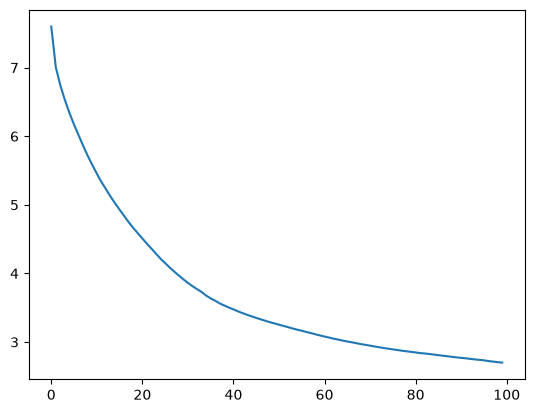

In [91]:
# Plot the history to analyze the success of training. Typically, for a neural network only 
# exploration, we would provide validation data to the fit method to allow us to check for 
# overfitting. 
# 
# Since our goal is to compare with scikit-learn models, this might not be the 
# best way to deal with this since we are using cross validation. A middle ground might be 
# the best solution so that we can perform early stopping.
#
# Note: this only works when the fit method is invoked. Need to add separate serialization of
# the history
plt.plot(knn.history.epoch, knn.history.history['loss'])
# plt.plot(knn.history.epoch, knn.history.history['val_loss'])

In [92]:
# Nested Cross Validation

# Separate features from the target without splitting into partitions
features = dataset.drop('Life expectancy ', axis=1)
targets = dataset['Life expectancy ']

In [93]:
# Create a list of scorers. These will be used during training and 
# testing by our nested CV setup below
scorers = {
    'R2': make_scorer(r2_score), 
    # Scikit-learn wants to make the refit metric (see cell below) as high as 
    # possible, which would be bad for error measures. We could therefore use the
    # builin names instead i.e. neg_mean_absolute_error, but the following is more
    # transparent
    'MAE': make_scorer(mean_absolute_error, greater_is_better=False), 
    'MSE': make_scorer(mean_squared_error, greater_is_better=False)
}

In [94]:
# Use GridSearchCV and cross_validate to perform nested cross validation. This works, but 
# doesn't allow for further analysis of the individual estimators created.
dt_pipe_grid2 = GridSearchCV(dt_pipe, dt_pipe_params, scoring=scorers, refit='MAE')
dt_pipe_results = pd.DataFrame(cross_validate(dt_pipe_grid2, features, targets, scoring=scorers))

In [95]:
# Investigate the results using pandas describe. This provides a conveniant way of 
# showing the mean and standard deviation of the test performance across all outer 
# test folds
dt_pipe_results.describe()

,fit_time,score_time,test_R2,test_MAE,test_MSE
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,2.205977,0.006567,0.823621,-2.585397,-12.593553
std,0.068481,0.000065,0.063670,0.154830,1.344111
min,2.159671,0.006489,0.715883,-2.804681,-14.983771
25%,2.162673,0.006519,0.815089,-2.626158,-12.143194
50%,2.176197,0.006570,0.858912,-2.621640,-12.059980
75%,2.207685,0.006604,0.861791,-2.458888,-12.026523
max,2.323659,0.006652,0.866431,-2.415620,-11.754296


In [ ]:
# A manual nested cross validation setup. Should be placed in a function 
# to provide ease of use and avoid repeating code.

# Create two cross validatin iterators, one for the outer final test with the test
# folds, and one inner for training and validation. Since this is a regression problem, we
# can do with KFold
outer_cv = KFold(n_splits=5)
inner_cv = KFold(n_splits=4)

# Create our grid search object that will perform the inner iteration. We provide the inner
# iterator through the cv argument.
dt_pipe_grid3 = GridSearchCV(dt_pipe, dt_pipe_params, cv=inner_cv)

# A list to store the results
dt_pipe_results3 = []
# Loop through the outer folds
for train_index, test_index in outer_cv.split(features):
    # Train and tune on the inner folds
    dt_pipe_grid3.fit(features.iloc[train_index], targets.iloc[train_index])
    # Make test predictions using the best model found
    predictions = dt_pipe_grid3.predict(features.iloc[test_index])
    # Go through all the metrics. Here I'm using only R2 for simplicity
    score_r2 = r2_score(targets.iloc[test_index], predictions)
    # Print the results for the current outer test fold. Should add functionality for going
    # through all scorers in our dictionary
    print(f'R2: {score_r2}')
    # Append the results and the best estimator to the results
    results = {
        'r2': score_r2, 
        'estimator': dt_pipe_grid3.best_estimator_
    }
    dt_pipe_results3.append(results)

print(dt_pipe_results3)

R2: 0.8667547348473275
R2: 0.809490422830199
R2: 0.8634512159535918
R2: 0.7211801992313311
R2: 0.8637361515664005
[{'r2': 0.8667547348473275, 'estimator': Pipeline(steps=[('encode',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('country',
                                                  OneHotEncoder(categories=[['Afghanistan',
                                                                             'Albania',
                                                                             'Algeria',
                                                                             'Angola',
                                                                             'Argentina',
                                                                             'Armenia',
                                                                             'Australia',
                                                                          